# Lab 09 — Decision Threshold Optimization Without Test Leakage

*AI Cybersecurity Masterclass · Lab 09 · AI60secLab*

**Companion video:** [▶ One Number Decides: Attack or Not?](https://www.youtube.com/watch?v=7yn55E7UxZ4&list=PLG4l6Ssi9A00)

**Research question:** Can a validation-selected decision threshold improve the security tradeoff between missed attacks and false alarms?

The official test data stays untouched until threshold selection is finished.

In [1]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

Project root: /home/claude/run/exec
Data folder : /home/claude/run/exec/data/raw


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

from src.data_loader import load_unsw
from src.preprocessing import split_xy, align_columns
from src.features import drop_identifier_like_columns
from src.models import random_forest_pipeline
from src.evaluation import binary_metrics, binary_metrics_frame
from src.thresholds import (
    threshold_sweep,
    choose_threshold,
    apply_threshold,
)

train, test = load_unsw(DATA_DIR)

X_full, y_full = split_xy(train, "label")
X_test, y_test = split_xy(test, "label")
X_full, X_test = align_columns(X_full, X_test)

X_full = drop_identifier_like_columns(X_full)
X_test = drop_identifier_like_columns(X_test)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    stratify=y_full,
    random_state=42,
)

In [3]:
model = random_forest_pipeline(X_train)
model.fit(X_train, y_train)

validation_scores = model.predict_proba(X_valid)[:, 1]

sweep = threshold_sweep(
    y_valid,
    validation_scores,
    beta=2.0,
    false_negative_cost=10.0,
    false_positive_cost=1.0,
)

f2_threshold, f2_row = choose_threshold(
    sweep,
    objective="f_beta",
)
cost_threshold, cost_row = choose_threshold(
    sweep,
    objective="cost",
)

print("Validation-selected F2 threshold:", round(f2_threshold, 3))
display(f2_row.to_frame().T)

print("Validation-selected illustrative-cost threshold:", round(cost_threshold, 3))
display(cost_row.to_frame().T)

Validation-selected F2 threshold: 0.21


,threshold,precision,recall,f_beta,false_positives,false_negatives,normalized_cost
16,0.21,0.928691,0.997947,0.983282,1829.0,49.0,0.066127


Validation-selected illustrative-cost threshold: 0.09


,threshold,precision,recall,f_beta,false_positives,false_negatives,normalized_cost
4,0.09,0.918004,0.999539,0.982094,2131.0,11.0,0.063903


The 10:1 false-negative/false-positive cost ratio is only an **illustrative research assumption**. A real security team must define its own operational costs.

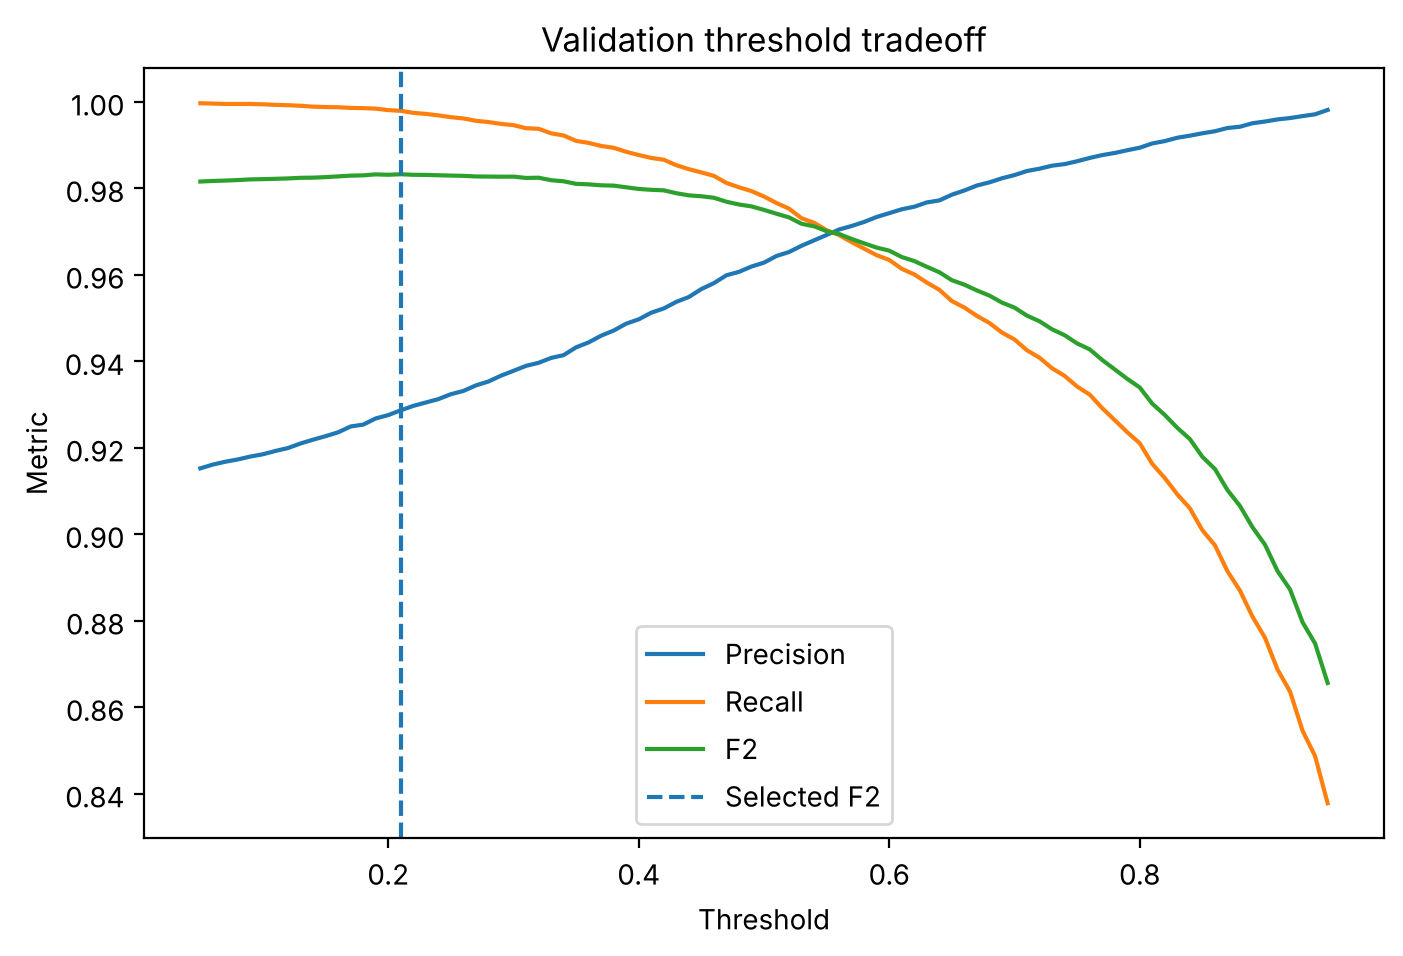

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sweep["threshold"], sweep["precision"], label="Precision")
ax.plot(sweep["threshold"], sweep["recall"], label="Recall")
ax.plot(sweep["threshold"], sweep["f_beta"], label="F2")
ax.axvline(f2_threshold, linestyle="--", label="Selected F2")
ax.set_xlabel("Threshold")
ax.set_ylabel("Metric")
ax.set_title("Validation threshold tradeoff")
ax.legend()
plt.show()

In [5]:
test_scores = model.predict_proba(X_test)[:, 1]

results = pd.concat([
    binary_metrics_frame(
        "Default 0.50",
        binary_metrics(
            y_test,
            apply_threshold(test_scores, 0.50),
            test_scores,
        ),
    ),
    binary_metrics_frame(
        f"Validation F2 {f2_threshold:.2f}",
        binary_metrics(
            y_test,
            apply_threshold(test_scores, f2_threshold),
            test_scores,
        ),
    ),
    binary_metrics_frame(
        f"Validation cost {cost_threshold:.2f}",
        binary_metrics(
            y_test,
            apply_threshold(test_scores, cost_threshold),
            test_scores,
        ),
    ),
])

display(results.round(4))

,accuracy,precision,recall,f1,false_positive_rate,false_negative_rate,roc_auc
model,,,,,,,
Default 0.50,0.8697,0.8149,0.9876,0.8930,0.2748,0.0124,0.9803
Validation F2 0.21,0.8154,0.7492,0.9992,0.8563,0.4098,0.0008,0.9803
Validation cost 0.09,0.8057,0.7393,0.9998,0.8500,0.4321,0.0002,0.9803


## Explain the result

Why is threshold tuning a separate decision problem from model training?

Why would tuning directly on the test set make your final performance estimate unreliable?